# Задача 5. Пуассоновское число фотонов и генераторы

## 1. Случайное число фотонов
`Source.n_photons(E)` разыгрывает $n \sim \mathrm{Poisson}(YE)$ (флаг `fluctuate=False` оставляет детерминированное $\mathrm{round}(YE)$ для сравнения). Все методы генерации фотонов используют этот розыгрыш.

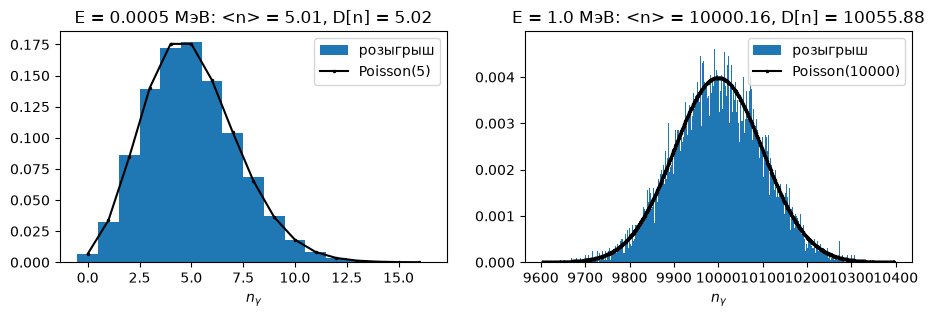

In [1]:
import time, types
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from source import Source
from detector import Detector

src = Source(Y=10_000, rng=50)

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for a_, E in zip(ax, (0.0005, 1.0)):
    ns = np.array([src.n_photons(E) for _ in range(20_000)])
    k = np.arange(ns.min(), ns.max() + 1)
    a_.hist(ns, bins=np.arange(ns.min() - 0.5, ns.max() + 1.5), density=True, label='розыгрыш')
    a_.plot(k, stats.poisson.pmf(k, src.Y * E), 'k.-', ms=3, label=f'Poisson({src.Y*E:g})')
    a_.set_title(f'E = {E} МэВ: <n> = {ns.mean():.2f}, D[n] = {ns.var():.2f}')
    a_.set_xlabel('$n_\\gamma$'); a_.legend()
plt.show()

## 2. Генератор фотонов

`Source.photons(E)` — функция с `yield`: при вызове она ничего не вычисляет, а возвращает объект-генератор. Каждый `next()` выполняет тело до следующего `yield` и отдаёт одно направление `(3,)`. Число фотонов разыгрывается один раз при первом `next()`; после последнего фотона генератор бросает `StopIteration`, и цикл `for` завершается.

```python
def photons(self, E, fluctuate=True):
    n = self.n_photons(E, fluctuate)
    for _ in range(n):
        yield self._isotropic(1)[0]
```

In [2]:
g = src.photons(1.0)
print(type(g), isinstance(g, types.GeneratorType))
print(next(g)); print(next(g))
rest = sum(1 for _ in g)
print("всего фотонов в событии:", 2 + rest)

<class 'generator'> True
[ 0.16273148 -0.86113272 -0.4816315 ]
[ 0.8526439  -0.32967461 -0.40535545]
всего фотонов в событии: 9987


## 3. Генератор пачками по 100 фотонов

`Source.photon_batches(E, batch_size=100)` отдаёт массивы `(100, 3)`; последняя пачка содержит остаток, так что полное число фотонов по-прежнему пуассоновское.

In [3]:
sizes = [len(b) for b in src.photon_batches(1.0)]
print(f"пачек: {len(sizes)}, первые: {sizes[:3]}, последняя: {sizes[-1]}, всего фотонов: {sum(sizes)}")

пачек: 101, первые: [100, 100, 100], последняя: 29, всего фотонов: 10029


## Сравнение скорости и памяти

Обработаем событие 1 МэВ детектором тремя способами: всё сразу (`directions`), по одному фотону, пачками по 100.

In [4]:
det = Detector(R=2.0, N=40, r=0.10, a=0.5, rng=5)
o = np.zeros(3)

def charge_all(E):
    return det.response(o, src.directions(E)).sum()

def charge_single(E):
    hits = np.zeros(det.N, int)
    for d in src.photons(E):
        k = det.trace(o, d[None])[0]
        if k >= 0:
            hits[k] += 1
    return det.photoelectrons(hits).sum()

def charge_batches(E, batch_size=100):
    hits = np.zeros(det.N, int)
    for b in src.photon_batches(E, batch_size):
        idx = det.trace(o, b)
        hits += np.bincount(idx[idx >= 0], minlength=det.N)
    return det.photoelectrons(hits).sum()

for name, f, n_ev in (("всё сразу", charge_all, 200),
                      ("по 1 фотону", charge_single, 5),
                      ("пачки по 100", charge_batches, 200)):
    t = time.perf_counter()
    Q = [f(1.0) for _ in range(n_ev)]
    dt = (time.perf_counter() - t) / n_ev
    print(f"{name:13s}: {dt*1e3:8.2f} мс/событие,  <Q> = {np.mean(Q):.1f}")

всё сразу    :     4.07 мс/событие,  <Q> = 123.2


по 1 фотону  :   555.44 мс/событие,  <Q> = 123.4


пачки по 100 :     8.72 мс/событие,  <Q> = 127.7


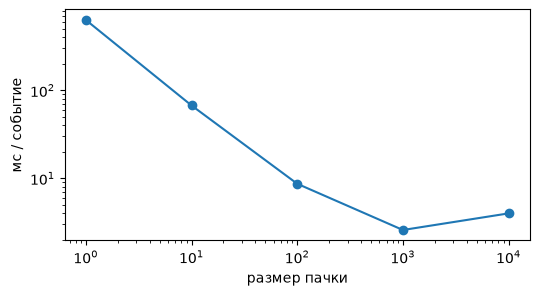

In [5]:
bs = [1, 10, 100, 1000, 10_000]
times = []
for b in bs:
    n_ev = 3 if b == 1 else 50
    t = time.perf_counter()
    for _ in range(n_ev):
        charge_batches(1.0, b)
    times.append((time.perf_counter() - t) / n_ev * 1e3)
plt.figure(figsize=(6, 3)); plt.loglog(bs, times, 'o-')
plt.xlabel('размер пачки'); plt.ylabel('мс / событие'); plt.show()

Статистика заряда не зависит от способа генерации:

In [6]:
Qa = np.array([charge_all(1.0) for _ in range(1000)])
Qb = np.array([charge_batches(1.0) for _ in range(1000)])
print(f"всё сразу:    <Q> = {Qa.mean():.2f} ± {Qa.std()/np.sqrt(1000):.2f}, σ = {Qa.std():.2f}")
print(f"пачки по 100: <Q> = {Qb.mean():.2f} ± {Qb.std()/np.sqrt(1000):.2f}, σ = {Qb.std():.2f}")
print("KS-тест p-value:", stats.ks_2samp(Qa, Qb).pvalue)

всё сразу:    <Q> = 125.15 ± 0.44, σ = 13.84
пачки по 100: <Q> = 125.98 ± 0.45, σ = 14.07
KS-тест p-value: 0.5362766985932181


## Что изменило случайное число фотонов

Сравним заряд при фиксированном числе фотонов (задачи 2–4) и при пуассоновском.

In [7]:
Qf = np.array([det.response(o, src.directions(1.0, fluctuate=False)).sum() for _ in range(1000)])
f = det.coverage()
Q0 = det.a * src.Y * f
print(f"число фотонов YE:      <Q> = {Qf.mean():.2f} ± {Qf.std()/np.sqrt(1000):.2f}, σ = {Qf.std():.2f}, теория {np.sqrt(Q0 * (1 + det.a * (1 - f))):.2f}")
print(f"Poisson(YE) фотонов:   <Q> = {Qa.mean():.2f} ± {Qa.std()/np.sqrt(1000):.2f}, σ = {Qa.std():.2f}, теория {np.sqrt(Q0 * (1 + det.a)):.2f}")

число фотонов YE:      <Q> = 125.24 ± 0.42, σ = 13.44, теория 13.64
Poisson(YE) фотонов:   <Q> = 125.15 ± 0.44, σ = 13.84, теория 13.70


**Выводы.**
- Генератор по одному фотону экономит память (в каждый момент хранится один вектор), но медленный: каждая итерация — это вызов Python и маленькие операции numpy, накладные расходы которых много больше самих вычислений.
- Пачки по 100 сочетают оба преимущества: внутри пачки вычисления векторные, а память ограничена размером пачки, а не числом фотонов в событии. Уже при пачке в 100 фотонов событие обрабатывается лишь примерно в 2 раза медленнее, чем «всё сразу», тогда как по одному фотону — более чем в 100 раз медленнее.
- Это важно для событий высокой энергии: при $E \sim 100$ МэВ событие — это $10^6$ фотонов, и массив `(n, N)` в `pmt_index` занимает сотни МБ; генератор пачками ограничивает его до `(100, N)`.
- Пуассоновское число фотонов почти не меняет ширину распределения заряда: теория даёт $\sigma_Q = 13.64$ вместо 13.70. На катоды попадает лишь $f = 2.5\%$ фотонов, поэтому основной вклад в флуктуации дают отбор фотонов и выбивание ф.э., а не их полное число. На 1000 событиях эта разница не видна.